In [29]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [18]:
data=pd.read_csv("../Data/blood1.csv")


In [19]:
data.head()

,Recency,Frequency,Monetary,Time,Class
0,2,50,12500,99,1
1,0,13,3250,28,1
2,1,17,4000,36,1
3,2,20,5000,45,1
4,1,24,6000,77,0


In [20]:
data.shape

(748, 5)

In [21]:
data.columns

Index(['Recency', 'Frequency', 'Monetary', 'Time', 'Class'], dtype='object')

In [22]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 748 entries, 0 to 747
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Recency    748 non-null    int64
 1   Frequency  748 non-null    int64
 2   Monetary   748 non-null    int64
 3   Time       748 non-null    int64
 4   Class      748 non-null    int64
dtypes: int64(5)
memory usage: 29.3 KB


In [23]:
data.isnull()

,Recency,Frequency,Monetary,Time,Class
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
743,False,False,False,False,False
744,False,False,False,False,False
745,False,False,False,False,False
746,False,False,False,False,False


In [24]:
data.isnull().sum()

Recency      0
Frequency    0
Monetary     0
Time         0
Class        0
dtype: int64

In [27]:
data["Class"].value_counts()

Class
0    570
1    178
Name: count, dtype: int64

In [28]:
data.describe()

,Recency,Frequency,Monetary,Time,Class
count,748.000000,748.000000,748.000000,748.000000,748.000000
mean,9.506684,5.516043,1378.676471,34.284759,0.237968
std,8.095396,5.841825,1459.826781,24.380307,0.426124
min,0.000000,1.000000,250.000000,2.000000,0.000000
25%,2.750000,2.000000,500.000000,16.000000,0.000000
50%,7.000000,4.000000,1000.000000,28.000000,0.000000
75%,14.000000,7.000000,1750.000000,50.000000,0.000000
max,74.000000,50.000000,12500.000000,99.000000,1.000000


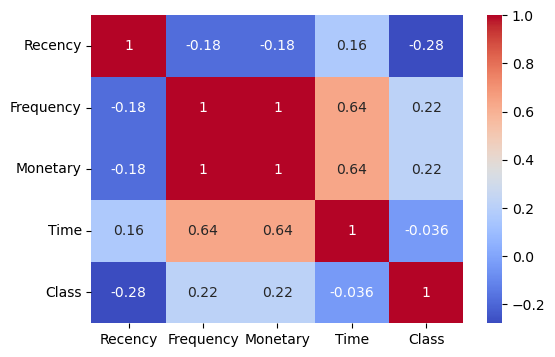

In [30]:
plt.figure(figsize=(6,4))
sns.heatmap(data.corr(),annot=True,cmap="coolwarm")
plt.show()

In [31]:
x=data.drop("Class",axis=1)
y=data["Class"]

In [32]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train ,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [34]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [36]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(x_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [37]:
import pickle

pickle.dump(scaler, open("../model/scaler.pkl", "wb"))

In [42]:
import os 
os.listdir("../model")

['scaler.pkl', 'model.pkl']

In [39]:
model.fit(x_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [41]:
import pickle
pickle.dump(model, open("../model/model.pkl","wb"))

In [43]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
y_pred=model.predict(x_test_scaled)

In [46]:
print("Accuracy:",accuracy_score(y_test,y_pred))
print("/nConfusion Matrix:/n",confusion_matrix(y_test,y_pred))
print("/nclassification Report:/n",classification_report(y_test,y_pred))

Accuracy: 0.76
/nConfusion Matrix:/n [[110   3]
 [ 33   4]]
/nclassification Report:/n               precision    recall  f1-score   support

           0       0.77      0.97      0.86       113
           1       0.57      0.11      0.18        37

    accuracy                           0.76       150
   macro avg       0.67      0.54      0.52       150
weighted avg       0.72      0.76      0.69       150



In [47]:


# sample input: Recency, Frequency, Monetary, Time
sample_input = np.array([[10, 5, 250, 12]])

sample_input_scaled = scaler.transform(sample_input)

prediction = model.predict(sample_input_scaled)

print("Prediction:", prediction)

Prediction: [0]


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
